# Exploratory Data Analysis: Diabetes

Run from the repo root or from `notebooks/`. Figures are saved to `report/figures/`.

In [9]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option('display.max_columns', None)
pd.set_option('display.width', 1000)

sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['font.size'] = 11

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'data' / 'diabetes_clean.csv').is_file())

output_dir = ROOT / 'report' / 'figures'
output_dir.mkdir(parents=True, exist_ok=True)

data_path = ROOT / 'data' / 'diabetes_clean.csv'
df = pd.read_csv(data_path)

print("Dataset Shape")
print(f"Rows: {df.shape[0]}, Columns: {df.shape[1]}\n")
print("First 5 Rows")
df.head()

Dataset Shape
Rows: 768, Columns: 11

First 5 Rows


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome,PatientID,BMICategory
0,6,148.0,72.0,35.0,125.0,33.6,0.627,50,1,1,Obese
1,1,85.0,66.0,29.0,125.0,26.6,0.351,31,0,2,Overweight
2,8,183.0,64.0,29.0,125.0,23.3,0.672,32,1,3,Normal
3,1,89.0,66.0,23.0,94.0,28.1,0.167,21,0,4,Overweight
4,0,137.0,40.0,35.0,168.0,43.1,2.288,33,1,5,Obese


1. Target Class Distribution:
                 Count  Percentage (%)
0 (No Diabetes)    500            65.1
1 (Diabetes)       268            34.9


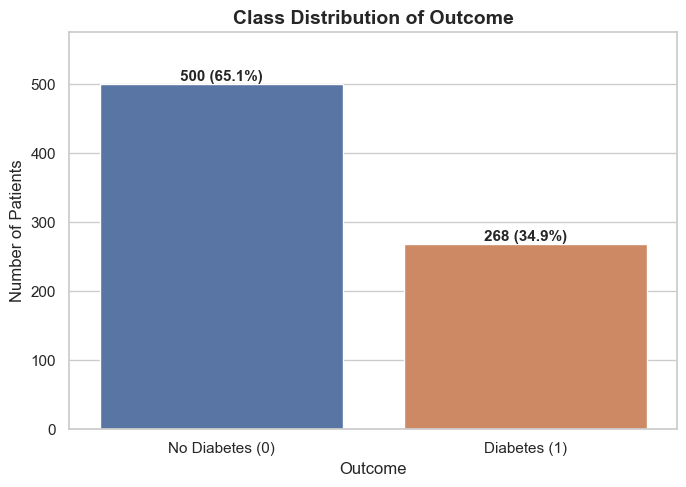

In [10]:
features = [
    'Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness',
    'Insulin', 'BMI', 'DiabetesPedigreeFunction', 'Age'
]
palette = ['#4C72B0', '#DD8452']

print("1. Target Class Distribution:")
outcome_counts = df['Outcome'].value_counts().sort_index()
outcome_pct = df['Outcome'].value_counts(normalize=True).sort_index() * 100
balance_df = pd.DataFrame({'Count': outcome_counts, 'Percentage (%)': outcome_pct.round(2)})
balance_df.index = ['0 (No Diabetes)', '1 (Diabetes)']
print(balance_df)

plt.figure(figsize=(7, 5))
ax = sns.countplot(data=df, x='Outcome', hue='Outcome', palette=palette, legend=False)
plt.title('Class Distribution of Outcome', fontsize=14, fontweight='bold')
plt.xlabel('Outcome')
plt.ylabel('Number of Patients')
plt.xticks([0, 1], ['No Diabetes (0)', 'Diabetes (1)'])
for p in ax.patches:
    height = int(p.get_height())
    if height > 0:
        ax.annotate(
            f'{height} ({height / len(df) * 100:.1f}%)',
            (p.get_x() + p.get_width() / 2., height),
            ha='center', va='bottom', fontsize=11, fontweight='bold'
        )
plt.ylim(0, df['Outcome'].value_counts().max() * 1.15)
plt.tight_layout()
plt.savefig(output_dir / '01_class_balance.png', dpi=300)
plt.show()

In [11]:
print("2. Descriptive Statistics By Outcome:")
stats_summary = df.groupby('Outcome')[features].agg(['mean', 'median', 'std']).round(2)
stats_summary.T

2. Descriptive Statistics By Outcome:


Outcome                               0       1
Pregnancies              mean      3.30    4.87
                         median    2.00    4.00
                         std       3.02    3.74
Glucose                  mean    110.68  142.13
                         median  107.50  140.00
                         std      24.71   29.57
BloodPressure            mean     70.92   75.12
                         median   72.00   74.00
                         std      11.93   11.95
SkinThickness            mean     27.73   31.69
                         median   29.00   29.00
                         std       8.55    8.66
Insulin                  mean    127.79  164.70
                         median  125.00  125.00
                         std      74.45  100.93
BMI                      mean     30.89   35.38
                         median   30.40   34.25
                         std       6.50    6.60
DiabetesPedigreeFunction mean      0.43    0.55
                         median    0.34    0.45
                         std       0.30    0.37
Age                      mean     31.19   37.07
                         median   27.00   36.00
                         std      11.67   10.97

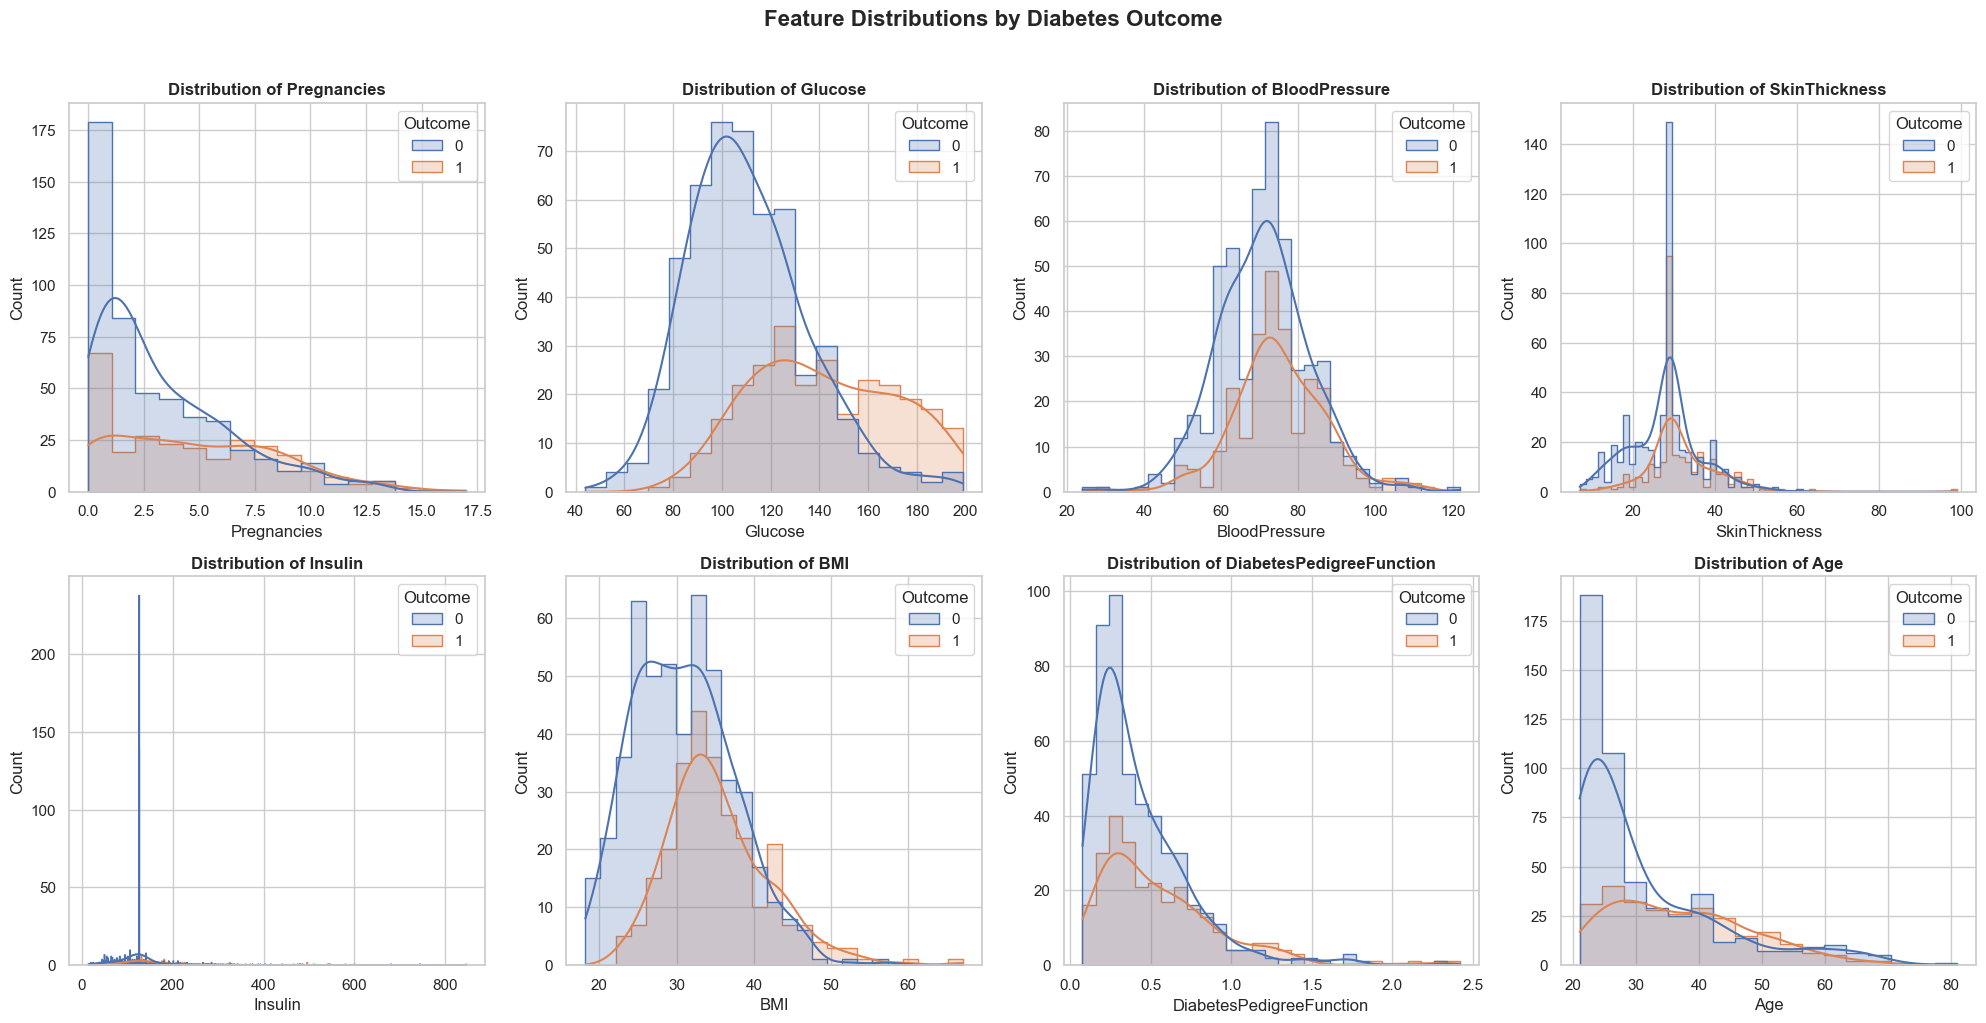

In [12]:
fig, axes = plt.subplots(2, 4, figsize=(20, 10))
axes = axes.flatten()
for i, col in enumerate(features):
    sns.histplot(data=df, x=col, hue='Outcome', kde=True, element="step",
                 palette=palette, ax=axes[i])
    axes[i].set_title(f'Distribution of {col}', fontweight='bold')
plt.suptitle('Feature Distributions by Diabetes Outcome', fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig(output_dir / '02_histograms_by_class.png', dpi=300, bbox_inches='tight')
plt.show()

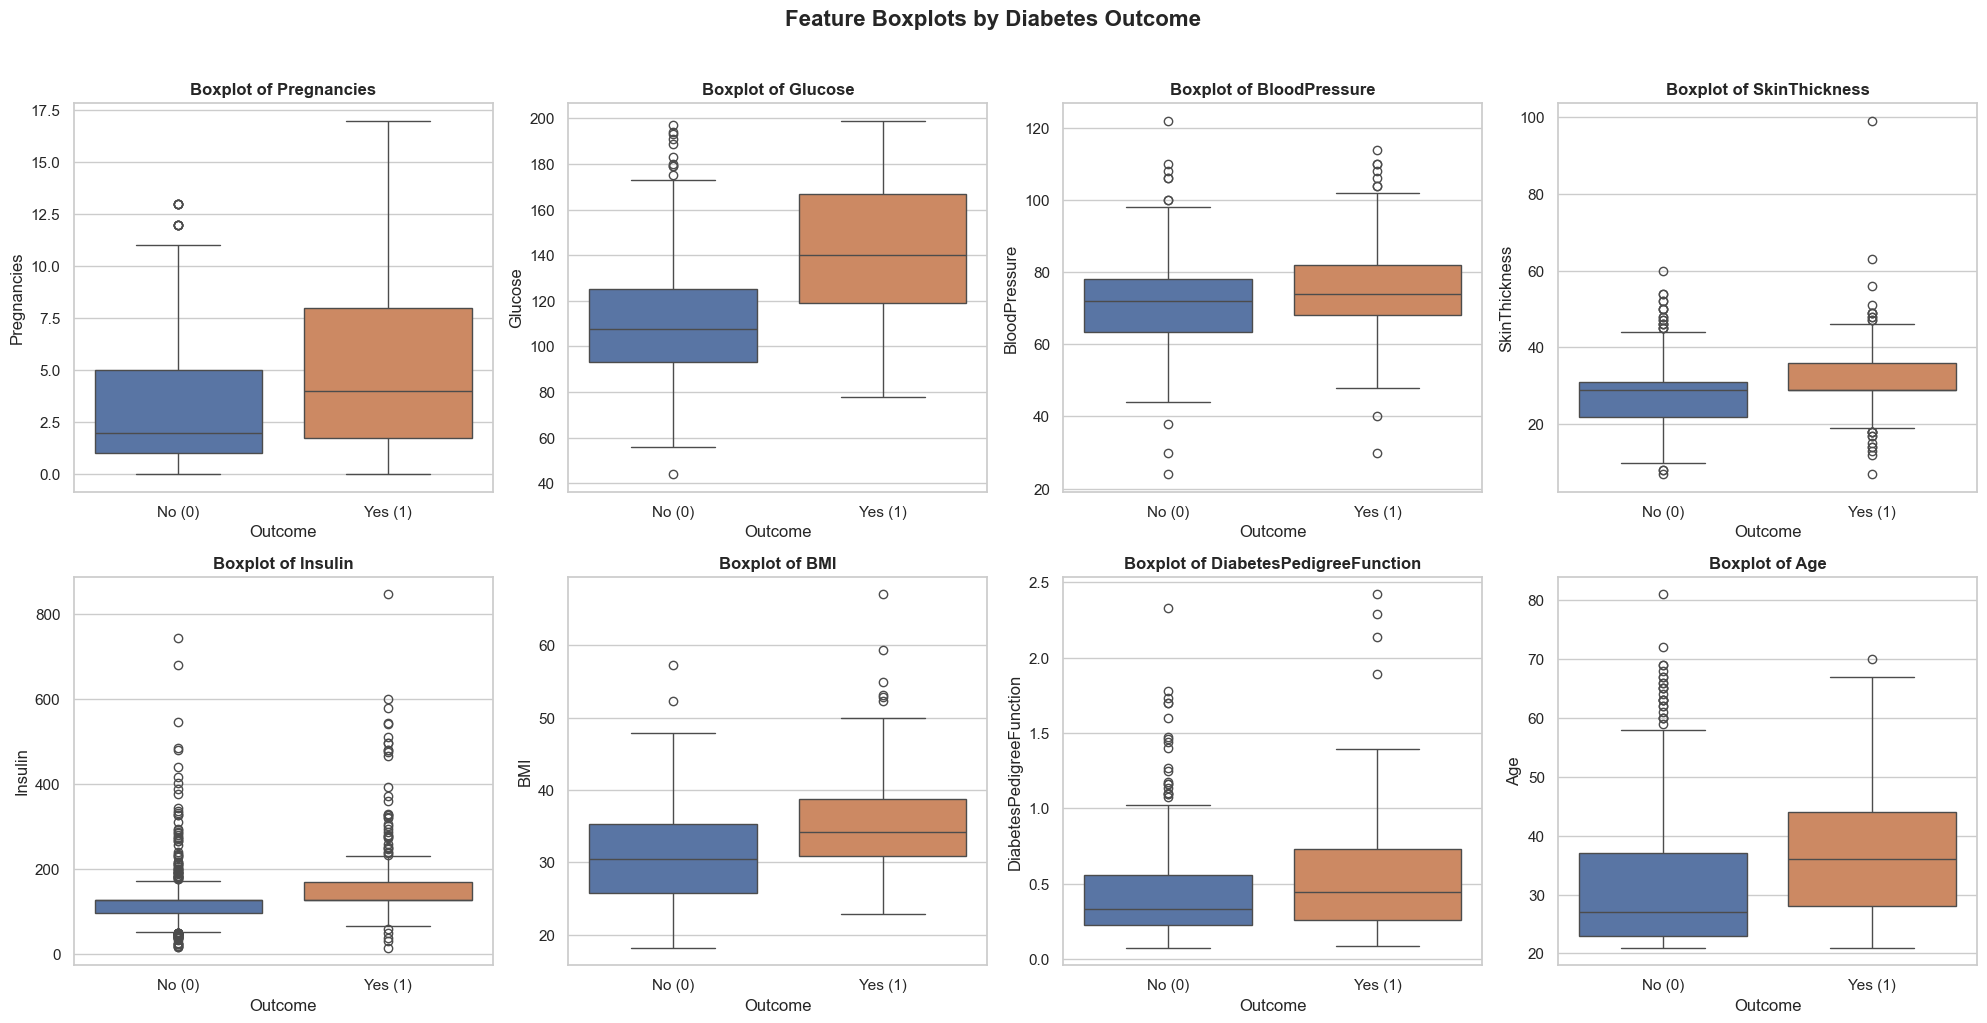

In [13]:
fig, axes = plt.subplots(2, 4, figsize=(20, 10))
axes = axes.flatten()
for i, col in enumerate(features):
    sns.boxplot(data=df, x='Outcome', y=col, hue='Outcome',
                palette=palette, ax=axes[i], legend=False)
    axes[i].set_title(f'Boxplot of {col}', fontweight='bold')
    axes[i].set_xticks([0, 1])
    axes[i].set_xticklabels(['No (0)', 'Yes (1)'])
plt.suptitle('Feature Boxplots by Diabetes Outcome', fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig(output_dir / '03_boxplots_by_class.png', dpi=300, bbox_inches='tight')
plt.show()

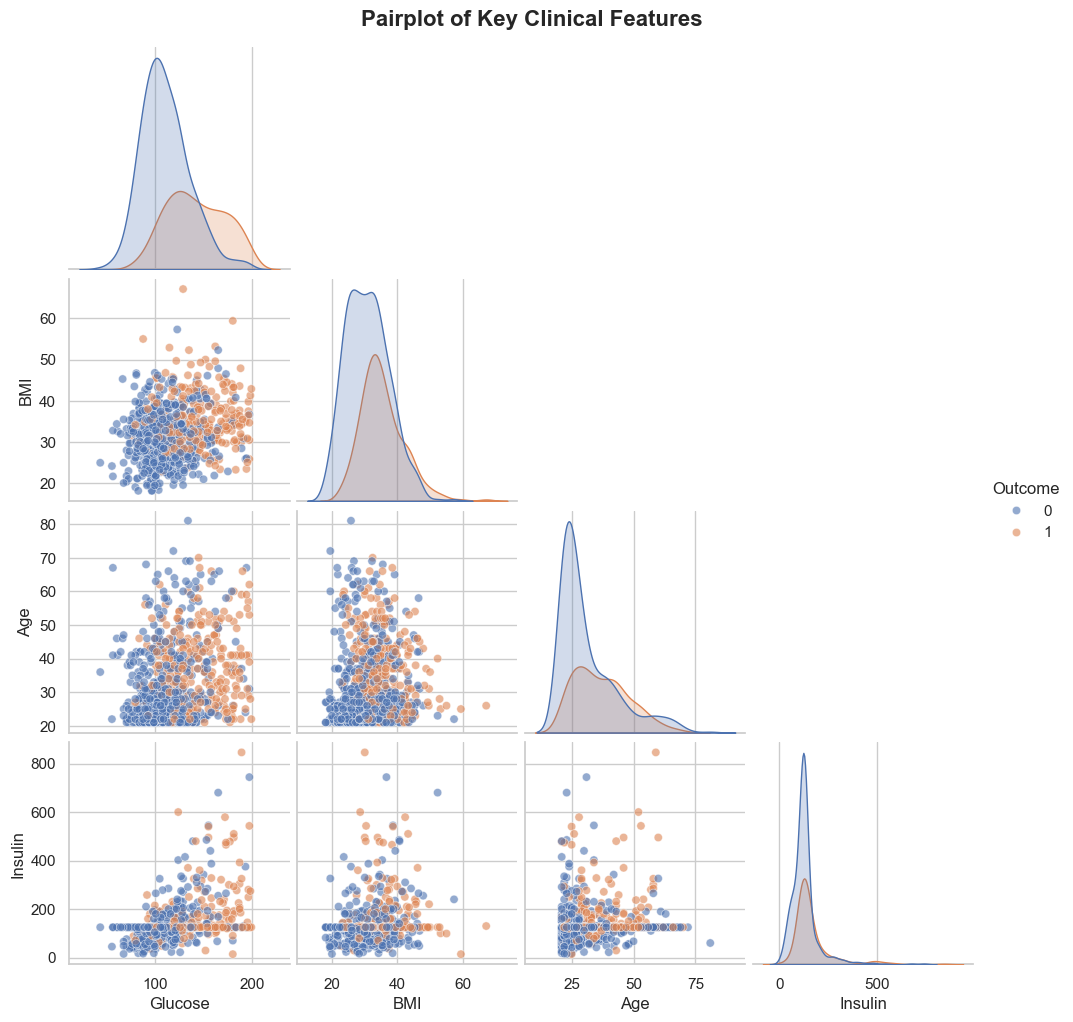

In [14]:
key_vars = ['Glucose', 'BMI', 'Age', 'Insulin', 'Outcome']
pairplot_fig = sns.pairplot(df[key_vars], hue='Outcome', palette=palette,
                            diag_kind='kde', corner=True, plot_kws={'alpha': 0.6})
pairplot_fig.figure.suptitle('Pairplot of Key Clinical Features', fontsize=16, fontweight='bold', y=1.02)
pairplot_fig.savefig(output_dir / '04_pairplot_key_features.png', dpi=300, bbox_inches='tight')
plt.show()

3. Pearson Correlation Matrix
                          Pregnancies  Glucose  BloodPressure  SkinThickness  Insulin    BMI  DiabetesPedigreeFunction    Age  Outcome
Pregnancies                     1.000    0.128          0.209          0.082    0.025  0.022                    -0.034  0.544    0.222
Glucose                         0.128    1.000          0.219          0.193    0.419  0.231                     0.137  0.267    0.493
BloodPressure                   0.209    0.219          1.000          0.192    0.045  0.281                    -0.002  0.325    0.166
SkinThickness                   0.082    0.193          0.192          1.000    0.156  0.543                     0.102  0.126    0.215
Insulin                         0.025    0.419          0.045          0.156    1.000  0.180                     0.127  0.097    0.204
BMI                             0.022    0.231          0.281          0.543    0.180  1.000                     0.153  0.026    0.312
DiabetesPedigreeFunction 

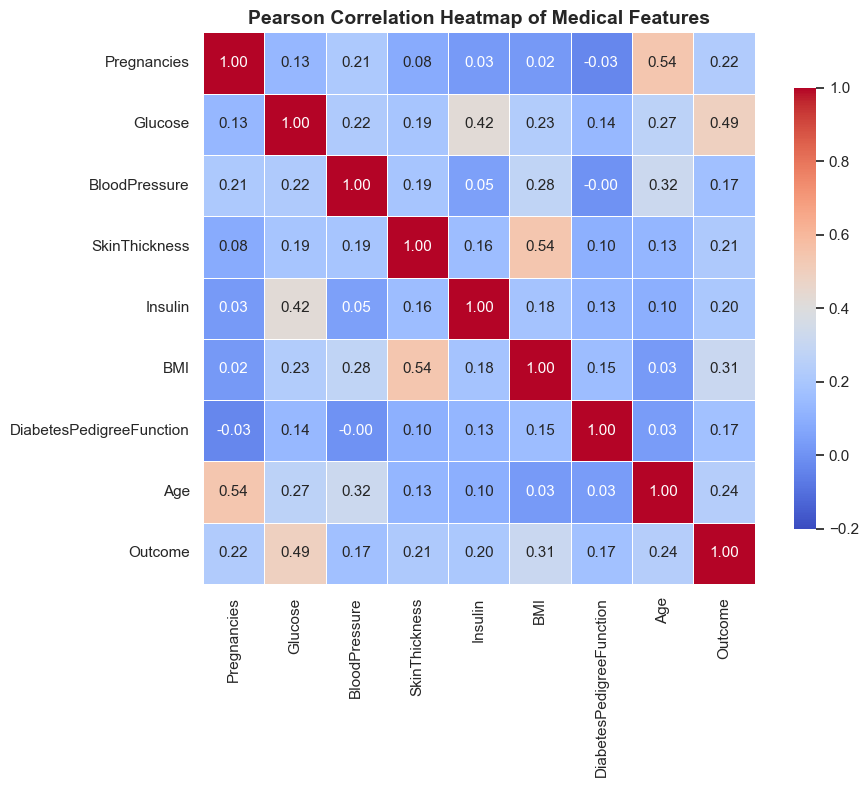

In [15]:
print("3. Pearson Correlation Matrix")
corr_matrix = df[features + ['Outcome']].corr()
print(corr_matrix.round(3), "\n")

print("4. Feature Correlation With Outcome")
outcome_corr = corr_matrix['Outcome'].drop('Outcome').sort_values(ascending=False)
print(outcome_corr.round(3))

plt.figure(figsize=(10, 8))
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap='coolwarm', vmin=-0.2, vmax=1.0,
            square=True, linewidths=0.5, cbar_kws={"shrink": .8})
plt.title('Pearson Correlation Heatmap of Medical Features', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig(output_dir / '05_correlation_heatmap.png', dpi=300)
plt.show()

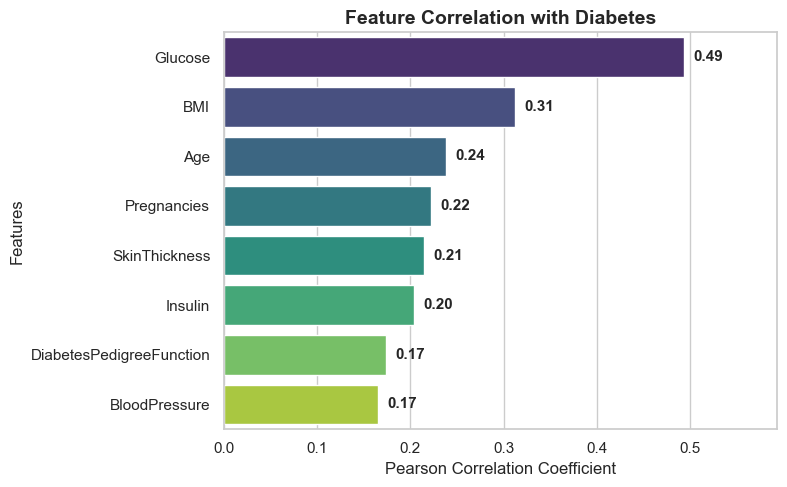

All 6 figures saved to 'c:\Users\igorl\OneDrive\Desktop\sugars_ml\report\figures'


In [16]:
plt.figure(figsize=(8, 5))
sns.barplot(x=outcome_corr.values, y=outcome_corr.index,
            hue=outcome_corr.index, palette='viridis', legend=False)
plt.title('Feature Correlation with Diabetes', fontsize=14, fontweight='bold')
plt.xlabel('Pearson Correlation Coefficient')
plt.ylabel('Features')
plt.xlim(min(0, outcome_corr.min() - 0.05), max(0.55, outcome_corr.max() + 0.1))
for i, v in enumerate(outcome_corr.values):
    plt.text(v + 0.01, i, f'{v:.2f}', va='center', fontweight='bold')
plt.tight_layout()
plt.savefig(output_dir / '06_outcome_correlations_bar.png', dpi=300)
plt.show()

print(f"All 6 figures saved to '{output_dir}'")

## Interpretation

Glucose, BMI and Age are the variables most strongly related to a diabetes diagnosis in this dataset. Glucose shows the clearest relationship: it has the highest correlation with Outcome, and its distribution is visibly shifted to higher values in the diabetes group in both the histograms and the boxplots. BMI and Age follow, with positive correlations that are weaker than Glucose; patients with diabetes tend to be heavier and older on average. The remaining variables (Pregnancies, Insulin, SkinThickness, DiabetesPedigreeFunction, BloodPressure) show weaker associations, and the heavily overlapping class distributions mean no single feature separates the classes cleanly. Note that Insulin and SkinThickness were imputed by class, so their histograms show artificial spikes at the imputed values, and their correlations with Outcome partly reflect the imputation rather than measured data. These are correlations, not causal effects, but they support using Glucose, BMI and Age as the main predictors in modelling.